# Phân cụm dữ liệu Iris bằng K-means, K = 3 (mục 8.2)

(a) Elbow và Silhouette, (b) cụm tìm được, (c) loài thật; (b), (c) chiếu xuống 2 chiều bằng PCA

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
DATA = Path('..') / 'data'   # thư mục data/

columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv(DATA / 'iris.data', header=None, names=columns)
X_scaled = StandardScaler().fit_transform(df[columns[:4]].to_numpy())
species = df['species'].to_numpy()

K_values = range(1, 11)
models = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled) for k in K_values]
kmeans = models[2]
pca = PCA(n_components=2).fit(X_scaled)
X_2d = pca.transform(X_scaled)

Vẽ hình và lưu ảnh.

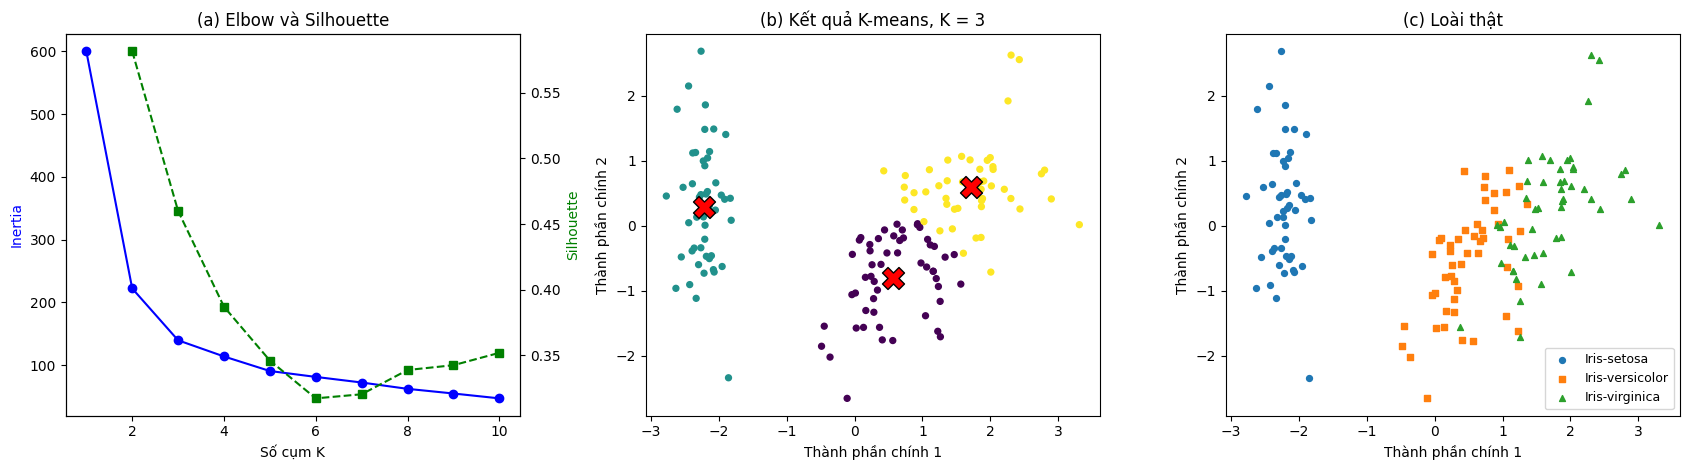

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax_right = axes[0].twinx()
axes[0].plot(K_values, [m.inertia_ for m in models], 'bo-', label='Inertia')
ax_right.plot(range(2, 11), [silhouette_score(X_scaled, m.labels_) for m in models[1:]], 'gs--', label='Silhouette')
axes[0].set_xlabel('Số cụm K'); axes[0].set_ylabel('Inertia', color='b'); ax_right.set_ylabel('Silhouette', color='g')
axes[0].set_title('(a) Elbow và Silhouette')
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans.labels_, cmap='viridis', s=18)
axes[1].scatter(*pca.transform(kmeans.cluster_centers_).T, marker='X', s=250, c='red', edgecolors='k')
axes[1].set_title('(b) Kết quả K-means, K = 3')
for name, marker in zip(np.unique(species), ['o', 's', '^']):
    axes[2].scatter(X_2d[species == name, 0], X_2d[species == name, 1], s=18, marker=marker, label=name)
axes[2].set_title('(c) Loài thật'); axes[2].legend(fontsize=9)
for ax in axes[1:]:
    ax.set_xlabel('Thành phần chính 1'); ax.set_ylabel('Thành phần chính 2')
fig.tight_layout()
fig.savefig(IMAGES / 'iris_kmeans.png', dpi=150)